<a href="https://colab.research.google.com/github/wira-jaa/praktikum-OOP/blob/main/AVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv('penjualan_nusantaramart.csv')
print(df.head())  # lihat 5 baris pertama
print(df.info())  # tipe data & jumlah data kosong
print(df.describe())  # ringkasan statistik

# rata-rata total pembelian per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))

   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             

Tugas Analisis 1
1. Kategori rata-rata transaksi tertinggi: Kategori yang berada di urutan  pertama pada output rata_kategori.
2. Cek data kosong (missing value): Bandingkan total baris (RangeIndex) dengan angka Non-Null Count pada output df.info(). Jika angkanya lebih kecil dari total baris, berarti kolom tersebut memiliki data kosong.
3. Perbandingan mean dan median: Jika nilai mean lebih besar daripada 50% (median) pada df.describe(), artinya data miring ke kanan (right-skewed) karena ada beberapa transaksi bernilai sangat besar (outlier). Jika hampir sama, sebarannya simetris/normal.

/tmp/ipykernel_1011/3245936885.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


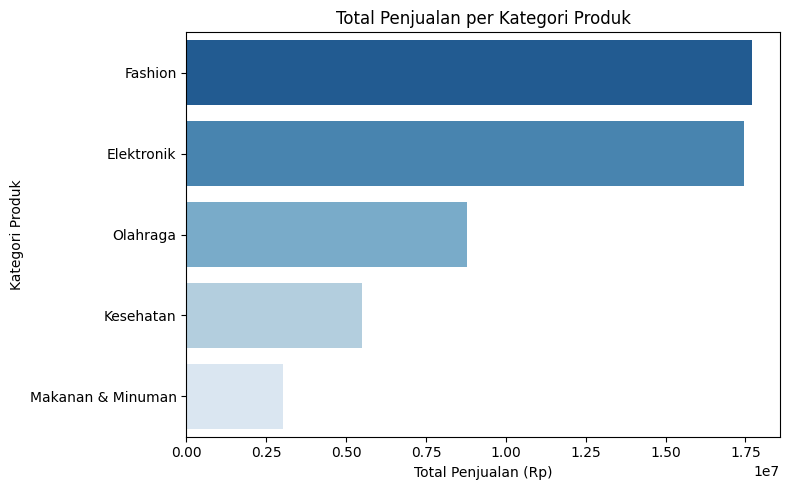

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

total_kategori = (
    df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
)
plt.figure(figsize=(8, 5))
sns.barplot(
    x=total_kategori.values, y=total_kategori.index, palette='Blues_r'
)
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

Tugas Analisis 2
1. Kategori tertinggi dan terendah: Tertinggi adalah batang paling atas (terpanjang), terendah adalah batang paling bawah (terpendek).
2. Rekomendasi bisnis: Jaga ketersediaan stok pada kategori terlaris agar tidak kehabisan, serta lakukan promo diskon atau bundling untuk mendongkrak penjualan pada kategori terendah.

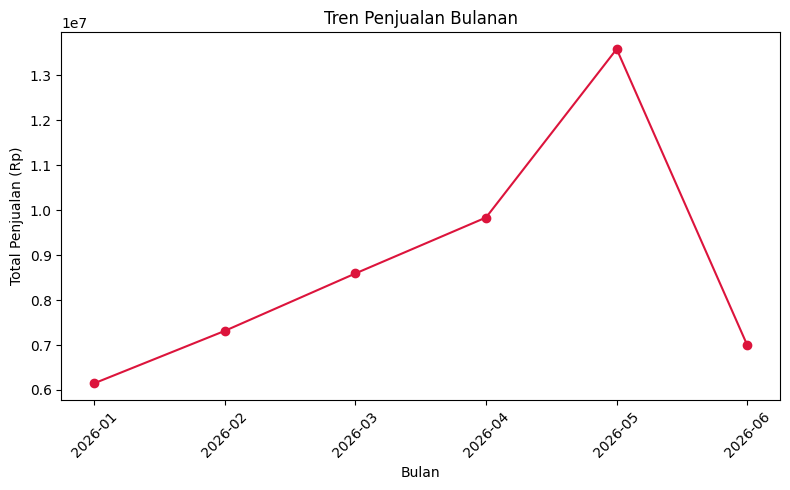

In [ ]:
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')
tren_bulanan = df.groupby('bulan')['total'].sum()

plt.figure(figsize=(8, 5))
plt.plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o',
    color='crimson',
)
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Tugas Analisis 3
1. Bulan penjualan tertinggi: Bulan pada titik puncak tertinggi di grafik.
2. Kemungkinan penyebab: Adanya momen musiman seperti hari raya, tanggal kembar (harbolnas), masa gajian, atau promo besar toko.
3. Pola tren: Cenderung naik jika garis bergerak ke atas, turun jika melemah ke bawah, atau fluktuatif jika sering naik-turun secara tajam antar-bulan.

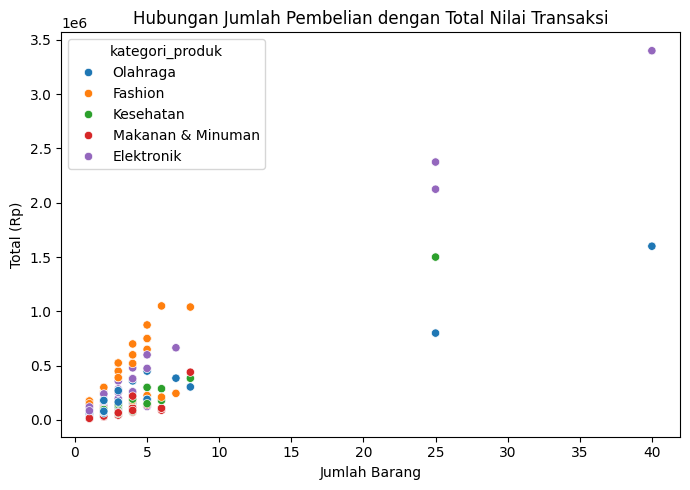

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

Tugas Analisis 4
1. Pola hubungan: Memiliki hubungan positif, artinya semakin banyak jumlah barang yang dibeli (jumlah), semakin besar pula total nilai transaksinya (total).
2. Titik jauh dari pola umum (outlier): Ada, yaitu titik-titik yang letaknya terpisah jauh di bagian kanan atau atas grafik. Kategorinya dapat dilihat dengan mencocokkan warna titik tersebut pada legenda.

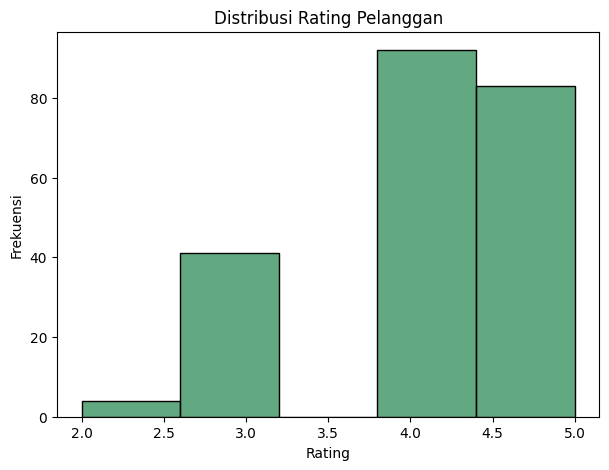

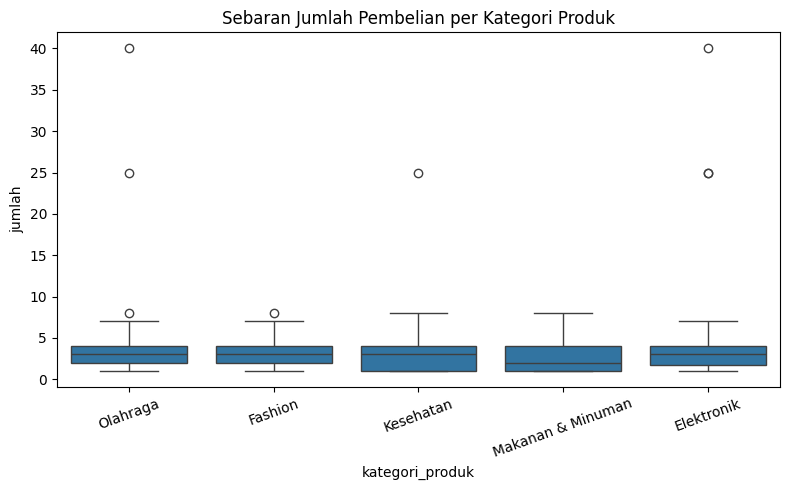

In [ ]:
# Histogram distribusi rating pelanggan
plt.figure(figsize=(7, 5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()

# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Tugas Analisis 5
1. Bentuk distribusi rating: Cenderung tinggi jika batang menumpuk di kanan (rating 4–5), rendah jika menumpuk di kiri (rating 1–2), atau merata jika tinggi semua batang hampir sama.
2. Kategori outlier & penyebabnya: Kategori yang memiliki titik-titik di luar garis batas atas boxplot. Penyebabnya kemungkinan karena pembelian grosir oleh reseller, kebutuhan acara/instansi, atau promo beli banyak lebih hemat.

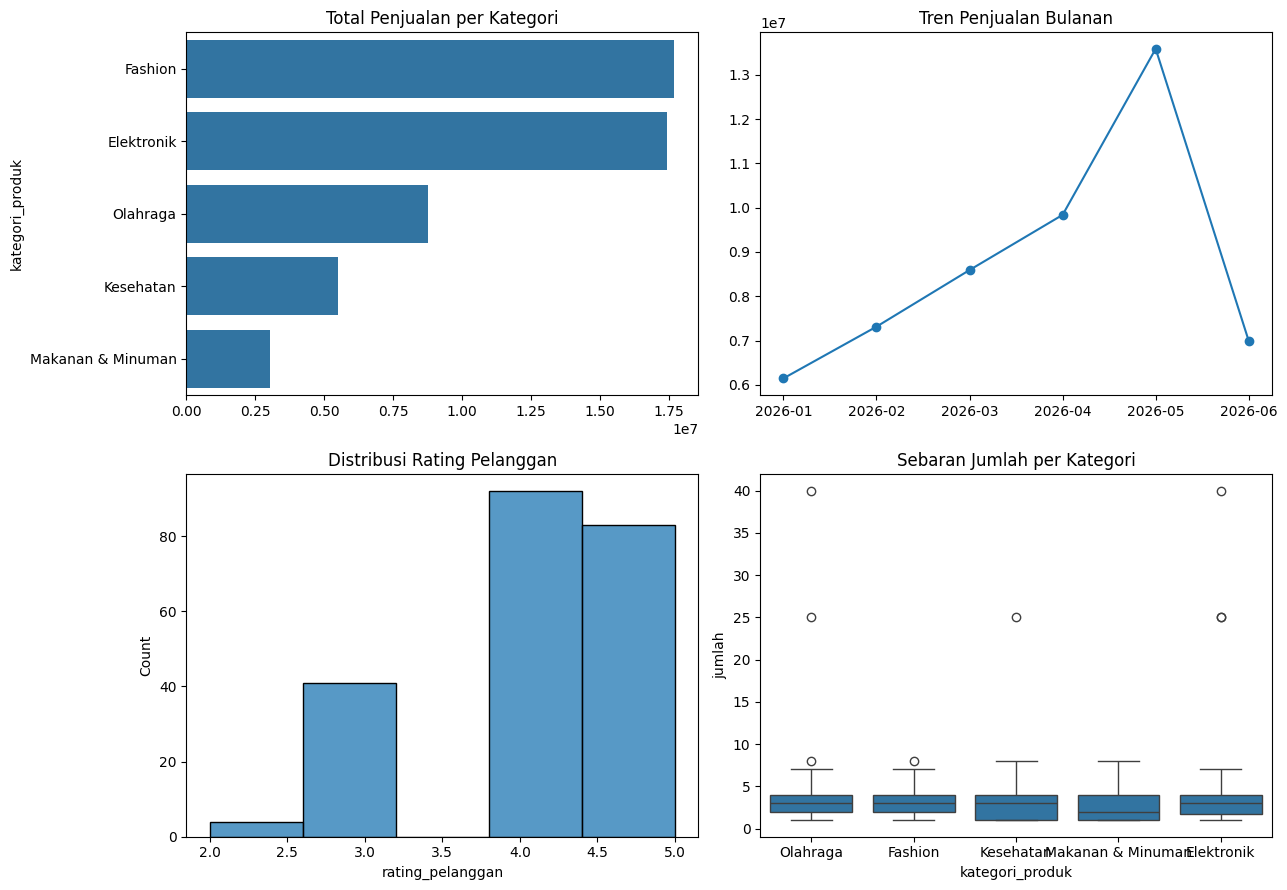

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0, 0])
axes[0, 0].set_title('Total Penjualan per Kategori')

axes[0, 1].plot(
    tren_bulanan.index.astype(str), tren_bulanan.values, marker='o'
)
axes[0, 1].set_title('Tren Penjualan Bulanan')

sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1, 0])
axes[1, 0].set_title('Distribusi Rating Pelanggan')

sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1, 1])
axes[1, 1].set_title('Sebaran Jumlah per Kategori')

plt.tight_layout()
plt.show()

Tugas Analisis 6
1. Keuntungan dashboard: Memudahkan pemantauan berbagai metrik penting sekaligus dalam satu layar secara ringkas, mempercepat pengambilan keputusan, serta mempermudah melihat hubungan antar-data.
2. Keputusan bisnis: Memfokuskan stok dan promosi pada kategori terlaris menjelang bulan puncak penjualan, membuat paket grosir untuk kategori yang banyak dibeli dalam jumlah besar, serta menjaga/meningkatkan kualitas layanan berdasarkan tren rating pelanggan.